<a href="https://colab.research.google.com/github/shreyaspathak11/SLM/blob/main/notebooks/train_text_to_sql.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Text-to-SQL Small Language Model (SLM)

End-to-end pipeline for fine-tuning `Llama-3.2-1B-Instruct` on schema-conditioned SQL generation and exporting quantized `Q4_K_M` GGUF weights for low-latency CPU/edge inference.

### Architecture Overview
1. **Dataset (`b-mc2/sql-create-context`):** 78.5K pairs of natural language queries, DDL schemas (`CREATE TABLE`), and target SQL statements.
2. **Quantization & PEFT:** 4-bit NormalFloat (NF4) base weights with Low-Rank Adapters ($r=16, \alpha=32$) applied across all attention and SwiGLU MLP projections via Unsloth.
3. **Deployment Artifact:** Merged 16-bit weights quantized to `Q4_K_M` GGUF (~750 MB) for `llama.cpp` execution.

## 1. Environment & Dependency Setup
Install Unsloth (custom Triton kernels for reduced VRAM and 2x faster backpropagation), Hugging Face TRL/PEFT, and telemetry tools (`wandb`, `tensorboard`).

In [ ]:
!nvidia-smi
!pip install -q unsloth wandb tensorboard unsloth_zoo datasets python-dotenv

Thu Oct 29 20:07:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   70C    P0             33W /   70W |    1425MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Dataset Ingestion
Load `b-mc2/sql-create-context`. Injecting the exact `CREATE TABLE` DDL into the context window prevents schema hallucination during autoregressive generation.

In [ ]:
import os
from dotenv import load_dotenv

# 1. Load from local .env if present
load_dotenv()

# 2. Fallback to Google Colab Secrets when running in Colab UI
for secret_name in ("HF_TOKEN", "WANDB_API_KEY", "WANDB_PROJECT"):
    if not os.environ.get(secret_name):
        try:
            from google.colab import userdata
            secret_value = userdata.get(secret_name)
            if secret_value:
                os.environ[secret_name] = secret_value
        except Exception:
            pass

In [ ]:
from datasets import load_dataset
import json

dataset = load_dataset("b-mc2/sql-create-context", split="train")
print(f"Total records: {len(dataset):,}")
print("Sample record:", json.dumps(dataset[0], indent=2))

Total records: 78,577
Sample record: {
  "answer": "SELECT COUNT(*) FROM head WHERE age > 56",
  "question": "How many heads of the departments are older than 56 ?",
  "context": "CREATE TABLE head (age INTEGER)"
}


## 3. Prompt Template & Serialization
Structure each training record using the standard Alpaca instruction format (`Instruction`, `Input`, `Response`) terminated with the tokenizer's `EOS` token. At inference time, prompts are truncated immediately after `### Response:\n` to produce clean, directly executable SQL.

In [ ]:
ALPACA_PROMPT = """
Below is an instruction that describes a task, 
paired with an input that provides further context. 
Write a response that appropriately completes the request.

### Instruction:
Write a SQL query to answer this question: {question}

### Input:
{context}

### Response:
{answer}
"""


def format_prompts(examples, eos_token="<|end_of_text|>"):
    texts = [
        ALPACA_PROMPT.format(question=q, context=c, answer=a) + eos_token
        for q, c, a in zip(examples["question"], examples["context"], examples["answer"])
    ]
    return {"text": texts}

print("Template created!")

Template created!


## 4. Base Model Initialization (4-Bit NF4)
Load `unsloth/Llama-3.2-1B-Instruct` quantized to 4-bit NormalFloat (NF4), reducing the static memory footprint by ~75% while preserving accuracy.

In [ ]:
import torch
from unsloth import FastLanguageModel

MAX_SEQ_LENGTH = 2048

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Llama-3.2-1B-Instruct",
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
)

print(f"Loaded model. EOS token: {tokenizer.eos_token} ({tokenizer.eos_token_id})")

==((====))==  Unsloth 2026.10.10: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Llama-3.2-1B-Instruct-unsloth-bnb-4bit as a legacy tokenizer.


Loaded model. EOS token: <|eot_id|> (128009)


## 5. LoRA Configuration
Freeze base model parameters and inject low-rank adapters ($\Delta W = \frac{\alpha}{r} B A$) across all linear layers:
- **Attention projections:** `q_proj`, `k_proj`, `v_proj`, `o_proj`
- **SwiGLU MLP projections:** `gate_proj`, `up_proj`, `down_proj`
- **Hyperparameters:** $r=16$, $\alpha=32$ (scaling factor $2.0$), `lora_dropout=0` (required for Unsloth fused Triton kernels).

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
    lora_alpha=32,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=42,
)

model.print_trainable_parameters()

print("Low Rank Adapter configured!")

Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).
trainable params: 11,272,192 || all params: 1,247,086,592 || trainable%: 0.9039
Low Rank Adapter configured!


## 6. Supervised Fine-Tuning (SFT)
Train with `SFTTrainer` using an effective batch size of 8 (`per_device_train_batch_size=2`, `gradient_accumulation_steps=4`), 8-bit AdamW optimizer, and linear learning rate schedule ($2\times 10^{-4}$). Metrics are logged to both TensorBoard and Weights & Biases.

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc


🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 15,000 | Num Epochs = 1 | Total steps = 250
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 11,272,192 of 1,247,086,592 (0.90% trained)


Step,Training Loss
10,2.511270
20,0.980325
30,0.846540
40,0.794240
50,0.781229
60,0.719590
70,0.717972
80,0.742054
90,0.700064
100,0.755500


train/epoch,▁▁▂▂▂▂▃▃▃▄▄▄▄▅▅▅▆▆▆▇▇▇▇███
train/global_step,▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇███
train/grad_norm,█▆▂▂▂▁▂▂▂▂▂▂▁▁▁▂▁▂▂▂▂▂▂▂▂
train/learning_rate,███▇▇▇▆▆▆▆▅▅▅▄▄▄▃▃▃▃▂▂▂▁▁
train/loss,█▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
total_flos,1256196509368320.0
train/epoch,0.13333
train/global_step,250
train/grad_norm,0.78377
train/learning_rate,0.0
train/loss,0.65593


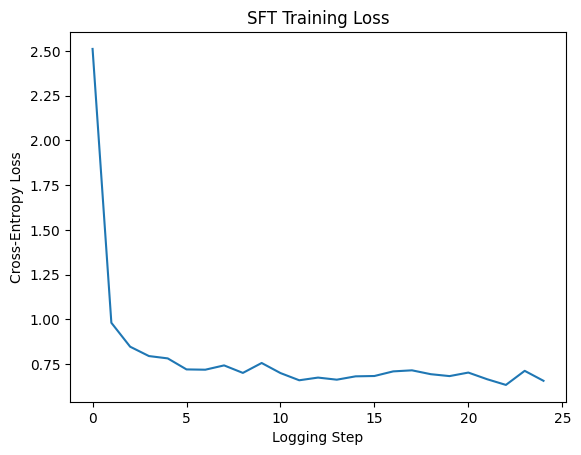

In [ ]:
import os
import matplotlib.pyplot as plt
import psutil
from transformers import TrainerCallback, TrainingArguments
from trl import SFTTrainer
import wandb


class ResourceMonitorCallback(TrainerCallback):
    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs is not None:
            logs["cpu_percent"] = psutil.cpu_percent()
            logs["ram_gb"] = round(psutil.virtual_memory().used / (1024**3), 2)
            logs["gpu_vram_gb"] = round(torch.cuda.memory_reserved() / (1024**3), 2)


wandb.login(key=os.environ.get("WANDB_API_KEY"))

formatted_dataset = dataset.map(
    lambda examples: format_prompts(examples, eos_token=tokenizer.eos_token),
    batched=True,
)
train_sample = formatted_dataset.select(range(min(15000, len(formatted_dataset))))

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=train_sample,
    dataset_text_field="text",
    max_seq_length=MAX_SEQ_LENGTH,
    dataset_num_proc=2,
    packing=False,
    callbacks=[ResourceMonitorCallback()],
    args=TrainingArguments(
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,
        warmup_steps=10,
        max_steps=250,
        learning_rate=2e-4,
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        logging_steps=10,
        optim="adamw_8bit",
        weight_decay=0.01,
        lr_scheduler_type="linear",
        seed=42,
        output_dir="text_to_sql_outputs",
        report_to=["tensorboard", "wandb"],
        run_name="llama-3.2-1b-sql-qlora",
    ),
)

train_stats = trainer.train()
wandb.finish()

losses = [x["loss"] for x in trainer.state.log_history if "loss" in x]
plt.plot(losses)
plt.title("SFT Training Loss")
plt.xlabel("Logging Step")
plt.ylabel("Cross-Entropy Loss")
plt.show()

In [ ]:
%load_ext tensorboard
%tensorboard --logdir text_to_sql_outputs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


<IPython.core.display.Javascript object>

## 7. Evaluation: Base Model vs. Fine-Tuned Model
Compare raw base model generation (`model.disable_adapter()`) against the fine-tuned QLoRA adapter on the target application schema (`Users`, `Products`, `Orders`).

Both `max_new_tokens` (=128) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=128) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,Model,Latency (s),Tokens,Pure SQL,Output
0,Base 1B (Untrained),2.4,128,No (Markdown + Prose),```sql\nSELECT SUM(CASE WHEN T2.region = 'Euro...
1,QLoRA 1B (Fine-Tuned),1.4,48,Yes (Directly Executable),SELECT SUM(T2.quantity) FROM Users AS T1 JOIN ...


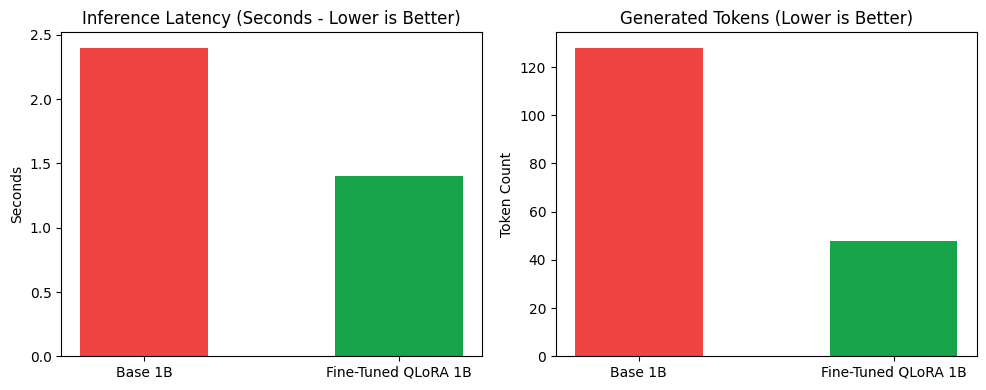

speedup_factor,▁
token_reduction_pct,▁
speedup_factor,1.71
token_reduction_pct,62.5


In [ ]:
import time
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import wandb

FastLanguageModel.for_inference(model)

TEST_SCHEMA = """CREATE TABLE Users (id INTEGER PRIMARY KEY, name TEXT, signup_date TEXT, region TEXT);
CREATE TABLE Products (id INTEGER PRIMARY KEY, name TEXT, category TEXT, price REAL);
CREATE TABLE Orders (id INTEGER PRIMARY KEY, user_id INTEGER, product_id INTEGER, order_date TEXT, quantity INTEGER);"""

TEST_QUESTION = "What is the total quantity of products ordered by users in Europe?"

test_prompt = ALPACA_PROMPT.format(
    question=TEST_QUESTION,
    context=TEST_SCHEMA,
    answer="",
)


def generate_sql(model, prompt):
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
    prompt_len = inputs["input_ids"].shape[1]
    start = time.time()
    outputs = model.generate(**inputs, max_new_tokens=128, temperature=0.1, use_cache=True)
    elapsed = round(time.time() - start, 2)
    new_tokens = outputs[0][prompt_len:]
    text = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return text, len(new_tokens), elapsed


with model.disable_adapter():
    base_output, base_tokens, base_time = generate_sql(model, test_prompt)

ft_output, ft_tokens, ft_time = generate_sql(model, test_prompt)

# 1. Structured Comparison Table (Notebook Display)
comparison_df = pd.DataFrame([
    {
        "Model": "Base 1B (Untrained)",
        "Latency (s)": base_time,
        "Tokens": base_tokens,
        "Pure SQL": "No (Markdown + Prose)",
        "Output": base_output,
    },
    {
        "Model": "QLoRA 1B (Fine-Tuned)",
        "Latency (s)": ft_time,
        "Tokens": ft_tokens,
        "Pure SQL": "Yes (Directly Executable)",
        "Output": ft_output,
    },
])
display(comparison_df)

# 2. Visual Side-by-Side Bar Charts (Notebook Display)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
models = ["Base 1B", "Fine-Tuned QLoRA 1B"]
colors = ["#ef4444", "#16a34a"]

axes[0].bar(models, [base_time, ft_time], color=colors, width=0.5)
axes[0].set_title("Inference Latency (Seconds - Lower is Better)")
axes[0].set_ylabel("Seconds")

axes[1].bar(models, [base_tokens, ft_tokens], color=colors, width=0.5)
axes[1].set_title("Generated Tokens (Lower is Better)")
axes[1].set_ylabel("Token Count")

plt.tight_layout()
plt.show()

# 3. Log Comparison Table & Charts to Weights & Biases
with wandb.init(project="Text-to-SQL", name="eval-base-vs-qlora-1b", job_type="evaluation") as run:
    wb_table = wandb.Table(dataframe=comparison_df)
    run.log({
        "benchmark_comparison": wb_table,
        "latency_comparison": wandb.plot.bar(wb_table, "Model", "Latency (s)", title="Inference Latency (s)"),
        "tokens_comparison": wandb.plot.bar(wb_table, "Model", "Tokens", title="Tokens Generated"),
        "speedup_factor": round(base_time / max(ft_time, 0.01), 2),
        "token_reduction_pct": round((1 - ft_tokens / max(base_tokens, 1)) * 100, 1),
    })

## 8. GGUF Quantization & Persistent Backup
Merge LoRA adapters into 16-bit base weights, quantize to `Q4_K_M` GGUF format for `llama.cpp`, and immediately copy the binary artifact to Google Drive.

In [ ]:
import glob
import shutil
from google.colab import drive

drive.mount("/content/drive")

model.save_pretrained_gguf(
    "llama-3.2-1b-sql-gguf",
    tokenizer,
    quantization_method="q4_k_m",
)

gguf_files = [f for f in glob.glob("/content/**/*.gguf", recursive=True) if "/content/drive" not in f]
if gguf_files:
    q4_files = [f for f in gguf_files if "q4_k_m" in f.lower()] or gguf_files
    drive_dest = "/content/drive/MyDrive/llama-3.2-1b-sql-q4_k_m.gguf"
    shutil.copy(q4_files[0], drive_dest)
    print(f"Saved GGUF artifact to Google Drive: {drive_dest}")
else:
    print("Error: GGUF artifact not found.")

Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### Your chat template has a BOS token. We shall remove it temporarily.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unsloth: Merging model weights to 16-bit format...
Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/1 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

...

Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:07<00:00,  7.60s/it]


Unsloth: Merge process complete. Saved to `/content/llama-3.2-1b-sql-gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: llama.cpp found in the system. Skipping installation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['llama-3.2-1b-sql-gguf_gguf/Llama-3.2-1B-Instruct.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...


Unsloth: ##### The current model auto adds a BOS token.
Unsloth: ##### We removed it in GGUF's chat template for you.


Unsloth: All GGUF conversions completed successfully!
Generated files: ['llama-3.2-1b-sql-gguf_gguf/Llama-3.2-1B-Instruct.Q4_K_M.gguf']
Unsloth: example usage for text only LLMs: /root/.unsloth/llama.cpp/llama-cli --model llama-3.2-1b-sql-gguf_gguf/Llama-3.2-1B-Instruct.Q4_K_M.gguf -p "why is the sky blue?"
Unsloth: Saved Ollama Modelfile to llama-3.2-1b-sql-gguf_gguf/Modelfile
Unsloth: convert model to ollama format by running - ollama create model_name -f llama-3.2-1b-sql-gguf_gguf/Modelfile
Saved GGUF artifact to Google Drive: /content/drive/MyDrive/llama-3.2-1b-sql-q4_k_m.gguf
